# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [27]:
!pip install -q kagglehub

import kagglehub
import os
import numpy as np
import pandas as pd
from scipy import stats as sstats
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Baixar dataset do Kaggle
path = kagglehub.dataset_download(
    "rewantbhriguvanshi/recent-movies-and-entertainment-dataset-20242026"
)

# Carregar CSV
df = pd.read_csv(
    os.path.join(path, "recent_movies_2024_2026.csv")
)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,title,release_year,release_month,release_day,genres,rating_out_of_10,vote_count,runtime_minutes,box_office_usd,budget_usd,director,screenwriter,cast,production_company,content_rating,language,country,synopsis,wikipedia_url,poster_url
0,The Mummy Murders,2024,January,2.0,"Horror, Mystery, Thriller",7.8,280952,138,45264640,12501632,NaN,Will Donahue,"Colin Bressler, Leila Annastasia Scott, Jason ...",Gravitas Ventures,R,English,United States,'The Mummy Murders' (2024) is a feature film d...,https://en.wikipedia.org/wiki/The_Mummy_Murders,https://images.unsplash.com/photo-148959984992...
1,DarkGame,2024,January,4.0,"Horror, Mystery, Thriller",7.6,109812,103,40487340,11440392,Howard J. Ford,"Gary Grant,Niall Johnson","Ed Westwick, Andrew P. Stephen, Natalya Tsvetk...",Gravitas Ventures,R,English,United States,'DarkGame' (2024) is a feature film directed b...,https://en.wikipedia.org/wiki/DarkGame,https://images.unsplash.com/photo-148959984992...
2,He Went That Way,2024,January,NaN,"Sci-Fi, Adventure",7.4,234187,128,29375529,22583686,Jeffrey Darling,Evan M. Wiener,"Jacob Elordi,Zachary Quinto,Patrick J. Adams",Vertical Entertainment/Mister Smith Entertainment,PG-13,English,United States,'He Went That Way' (2024) is a feature film di...,https://en.wikipedia.org/wiki/He_Went_That_Way,https://images.unsplash.com/photo-148959984992...
3,The Painter,2024,January,NaN,"Sci-Fi, Adventure",9.2,165532,158,28225644,21817096,Kimani Ray Smith,Brian Buccellato,"Charlie Weber,Jon Voight,Marie Avgeropoulos, M...",Republic Pictures,PG-13,English,United States,'The Painter' (2024) is a feature film directe...,https://en.wikipedia.org/wiki/The_Painter_(202...,https://images.unsplash.com/photo-148959984992...
4,The Bricklayer,2024,January,NaN,"Sci-Fi, Adventure",7.1,227023,92,29255541,22503694,Renny Harlin,"Hanna Weg, Matt Johnson","Aaron Eckhart,Nina Dobrev,Tim Blake Nelson,Ilf...",Vertical Entertainment/Millennium Media,PG-13,English,United States,'The Bricklayer' (2024) is a feature film dire...,https://en.wikipedia.org/wiki/The_Bricklayer,https://images.unsplash.com/photo-148959984992...


In [28]:
# Mudar para se tornar a classe
df['rating_out_of_10'] = np.where(df['rating_out_of_10'] < 7, 'Abaixo de 7', '7 ou mais')
# Mudar para escala logaritmica
df["box_office_usd"] = np.log(df["box_office_usd"])
df["budget_usd"] = np.log(df["budget_usd"])

In [29]:
df.head()

,title,release_year,release_month,release_day,genres,rating_out_of_10,vote_count,runtime_minutes,box_office_usd,budget_usd,director,screenwriter,cast,production_company,content_rating,language,country,synopsis,wikipedia_url,poster_url
0,The Mummy Murders,2024,January,2.0,"Horror, Mystery, Thriller",7 ou mais,280952,138,17.628037,16.341370,NaN,Will Donahue,"Colin Bressler, Leila Annastasia Scott, Jason ...",Gravitas Ventures,R,English,United States,'The Mummy Murders' (2024) is a feature film d...,https://en.wikipedia.org/wiki/The_Mummy_Murders,https://images.unsplash.com/photo-148959984992...
1,DarkGame,2024,January,4.0,"Horror, Mystery, Thriller",7 ou mais,109812,103,17.516500,16.252661,Howard J. Ford,"Gary Grant,Niall Johnson","Ed Westwick, Andrew P. Stephen, Natalya Tsvetk...",Gravitas Ventures,R,English,United States,'DarkGame' (2024) is a feature film directed b...,https://en.wikipedia.org/wiki/DarkGame,https://images.unsplash.com/photo-148959984992...
2,He Went That Way,2024,January,NaN,"Sci-Fi, Adventure",7 ou mais,234187,128,17.195673,16.932738,Jeffrey Darling,Evan M. Wiener,"Jacob Elordi,Zachary Quinto,Patrick J. Adams",Vertical Entertainment/Mister Smith Entertainment,PG-13,English,United States,'He Went That Way' (2024) is a feature film di...,https://en.wikipedia.org/wiki/He_Went_That_Way,https://images.unsplash.com/photo-148959984992...
3,The Painter,2024,January,NaN,"Sci-Fi, Adventure",7 ou mais,165532,158,17.155741,16.898204,Kimani Ray Smith,Brian Buccellato,"Charlie Weber,Jon Voight,Marie Avgeropoulos, M...",Republic Pictures,PG-13,English,United States,'The Painter' (2024) is a feature film directe...,https://en.wikipedia.org/wiki/The_Painter_(202...,https://images.unsplash.com/photo-148959984992...
4,The Bricklayer,2024,January,NaN,"Sci-Fi, Adventure",7 ou mais,227023,92,17.191580,16.929190,Renny Harlin,"Hanna Weg, Matt Johnson","Aaron Eckhart,Nina Dobrev,Tim Blake Nelson,Ilf...",Vertical Entertainment/Millennium Media,PG-13,English,United States,'The Bricklayer' (2024) is a feature film dire...,https://en.wikipedia.org/wiki/The_Bricklayer,https://images.unsplash.com/photo-148959984992...


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:**
O dataset de filmes e entretenimento tem variáveis quantitativas(exemplo: quantidade de votos, orçamento, bilheteria), qualitativas(exemplo: título, diretor, roteirista) e possui como alvo rating_out_of_10

### Dimensão e Tipos de Dados

In [30]:
df.shape

(916, 20)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 916 entries, 0 to 915
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   title               916 non-null    str    
 1   release_year        916 non-null    int64  
 2   release_month       916 non-null    str    
 3   release_day         240 non-null    float64
 4   genres              916 non-null    str    
 5   rating_out_of_10    916 non-null    str    
 6   vote_count          916 non-null    int64  
 7   runtime_minutes     916 non-null    int64  
 8   box_office_usd      916 non-null    float64
 9   budget_usd          916 non-null    float64
 10  director            611 non-null    str    
 11  screenwriter        894 non-null    str    
 12  cast                916 non-null    str    
 13  production_company  916 non-null    str    
 14  content_rating      916 non-null    str    
 15  language            916 non-null    str    
 16  country            

In [32]:
df.describe()

,release_year,release_day,vote_count,runtime_minutes,box_office_usd,budget_usd
count,916.000000,240.000000,916.000000,916.000000,916.000000,916.000000
mean,2024.975983,15.679167,190883.281659,128.033843,17.297582,16.901221
std,0.816143,9.011452,97582.137783,21.704472,0.435715,0.371058
min,2024.000000,1.000000,7128.000000,90.000000,17.046813,16.199612
25%,2024.000000,7.000000,119065.500000,110.750000,17.142278,16.865544
50%,2025.000000,16.000000,179263.000000,129.000000,17.185638,16.906471
75%,2026.000000,24.000000,253092.000000,146.000000,17.262090,16.951936
max,2026.000000,31.000000,452490.000000,164.000000,20.051294,18.958614


### Duplicadas

In [33]:
df.duplicated().sum()

np.int64(0)

## 2. Dados Faltantes

In [34]:
df.isna().sum()

title                   0
release_year            0
release_month           0
release_day           676
genres                  0
rating_out_of_10        0
vote_count              0
runtime_minutes         0
box_office_usd          0
budget_usd              0
director              305
screenwriter           22
cast                    0
production_company      0
content_rating          0
language                0
country                 0
synopsis                0
wikipedia_url           0
poster_url              0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim, realease_day, director e screenwriter possuem dados ausentes


#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos três features 'realease_day', 'director' e 'screenwriter' com dados ausentes.

Pela fonte de dados observamos que:

* realease_day - Dia que o filme foi lançado
* director - Diretor do filme
* screenwriter - Roteiristas

*Como os dados foram coletados:*
- O conjunto de dados foi disponibilizado na plataforma Kaggle e reúne informações sobre filmes e conteúdos de entretenimento recentes, abrangendo o período de 2024 a 2026. Os dados são organizados em formato tabular, contendo informações relacionadas às produções cinematográficas e seus atributos.

*Qual a natureza da fonte de dados:*
- Trata-se de uma fonte de dados secundária, composta por informações agregadas de plataformas de entretenimento. Por lidar com lançamentos do período de 2024 a 2026, é comum encontrar ausências: filmes em pré-produção ou com datas ajustáveis frequentemente omitem o release_day exato, enquanto produções independentes, documentários ou projetos colaborativos podem não ter o director ou screenwriter explicitamente cadastrados nos metadados originais.



**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [35]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['release_day', 'director', 'screenwriter']
release_day     676
director        305
screenwriter     22
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

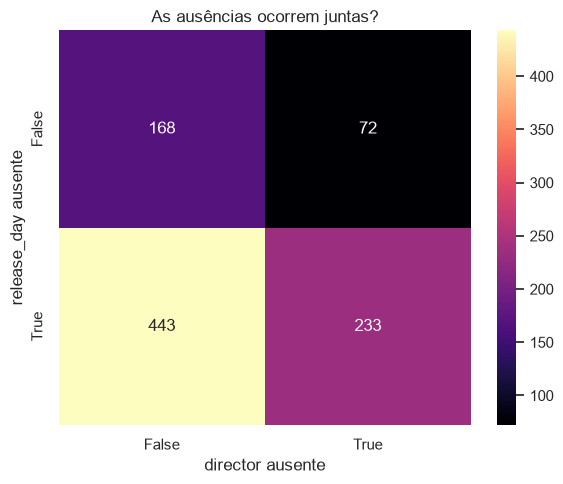

In [37]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

233 linhas possuem ausência de dia de lançamento e de diretor ao mesmo tempo

Não parecem eventos independentes, a ocorrência de 25,4%(233/916) de casos simultâneos de ausência de dia de lançamento e de diretor leva a crer que existe uma dependencia, descartando a hipótese de mecanismos aleatórios


*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o filme é um projeto independente ou conceitual que deliberadamente optou por não ter um diretor único creditado (ou não fixou uma data de estreia por não planejar um lançamento tradicional nos cinemas), e por isso a informação simplesmente não existe., isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o script de web scraping não conseguiu extrair a data e o diretor devido a uma variação no layout da página da web, ou o catálogo de onde os dados foram coletados priorizou apenas os metadados de grandes produções, deixando o cadastro de títulos menores incompleto por padrão do sistema — independentemente de quem seja o diretor ou de qual seja a data real.— isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [38]:
VARS_QUANT = ["release_year", "release_day", "vote_count", "runtime_minutes", "box_office_usd", "budget_usd"]
VARS_QUALI = ["title", "release_month", "genres","rating_out_of_10", "director", "screenwriter", "cast", "production_company", "content_rating", "language", "country", "synopsis", "wikipedia_url", "poster_url"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
release_year,2024.98,2025.00,0.82,2024.00,2026.00,0.04,-1.50
release_day,15.68,16.00,9.01,1.00,31.00,-0.08,-1.26
vote_count,190883.28,179263.00,97582.14,7128.00,452490.00,0.46,-0.37
runtime_minutes,128.03,129.00,21.70,90.00,164.00,-0.08,-1.17
box_office_usd,17.30,17.19,0.44,17.05,20.05,5.35,30.36
budget_usd,16.90,16.91,0.37,16.20,18.96,3.10,17.22


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

box_office_usd(bilheteria) e budget_usd(orçamento) possuem skewness acima de 1, portanto parecem assimétricas, e também possuem kurtosis maior que 2 em módulo, ou seja, parecem ter cauda pesada

Isso é coerente com o que vocês esperariam ?

Sim, porque existem produções que possuem orçamentos e bilheterias altíssimas e isso puxa a média para cima

### Distribuições de dados

Onde fizer sentido, comparamos "Abaixo de 7" (rosa) vs. "7 ou mais" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


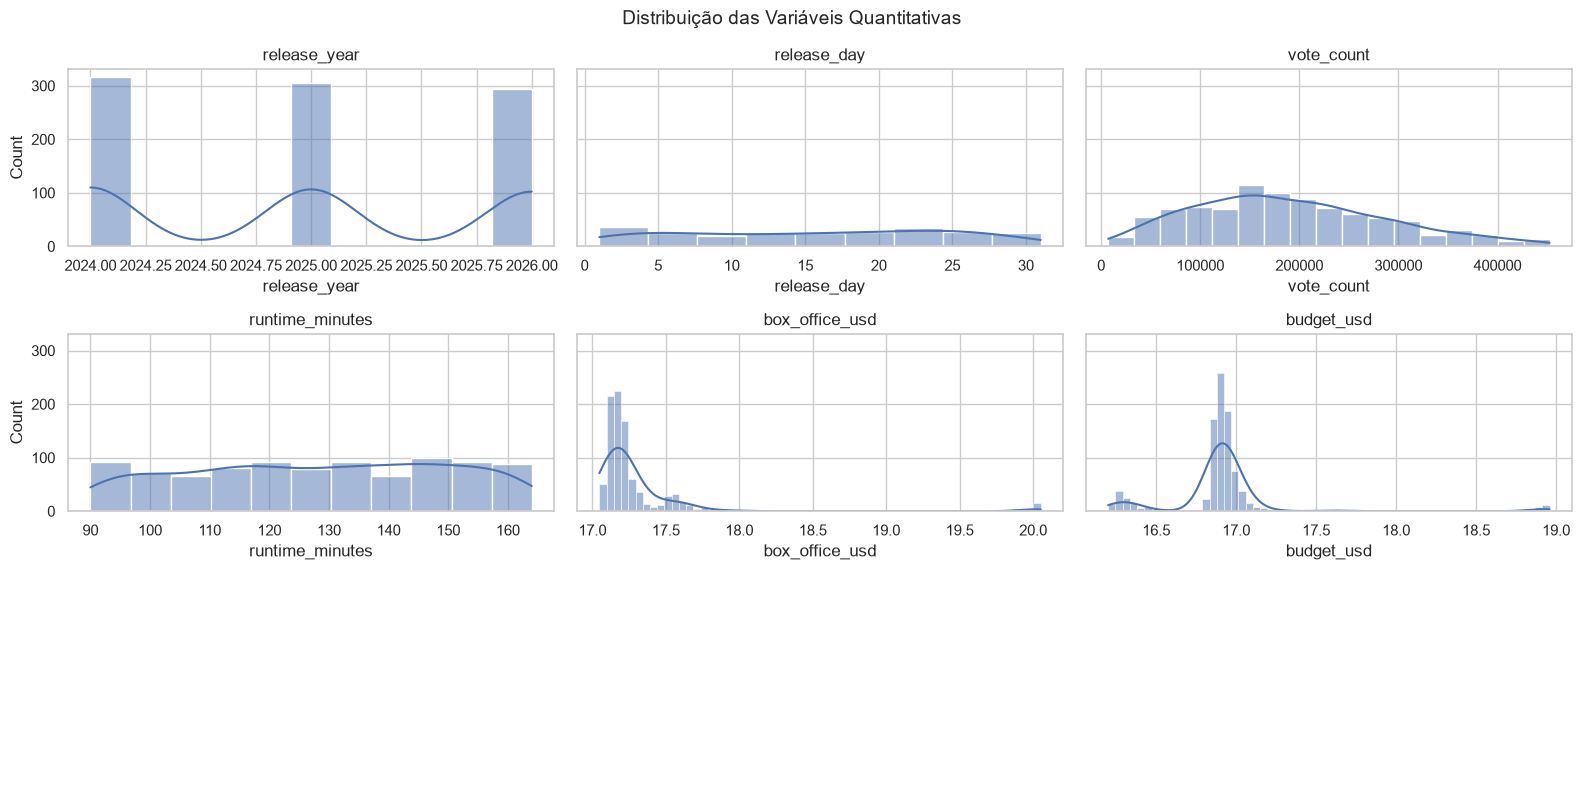

In [39]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color="#4C72B0", ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas", fontsize=14)
plt.tight_layout()
plt.show()

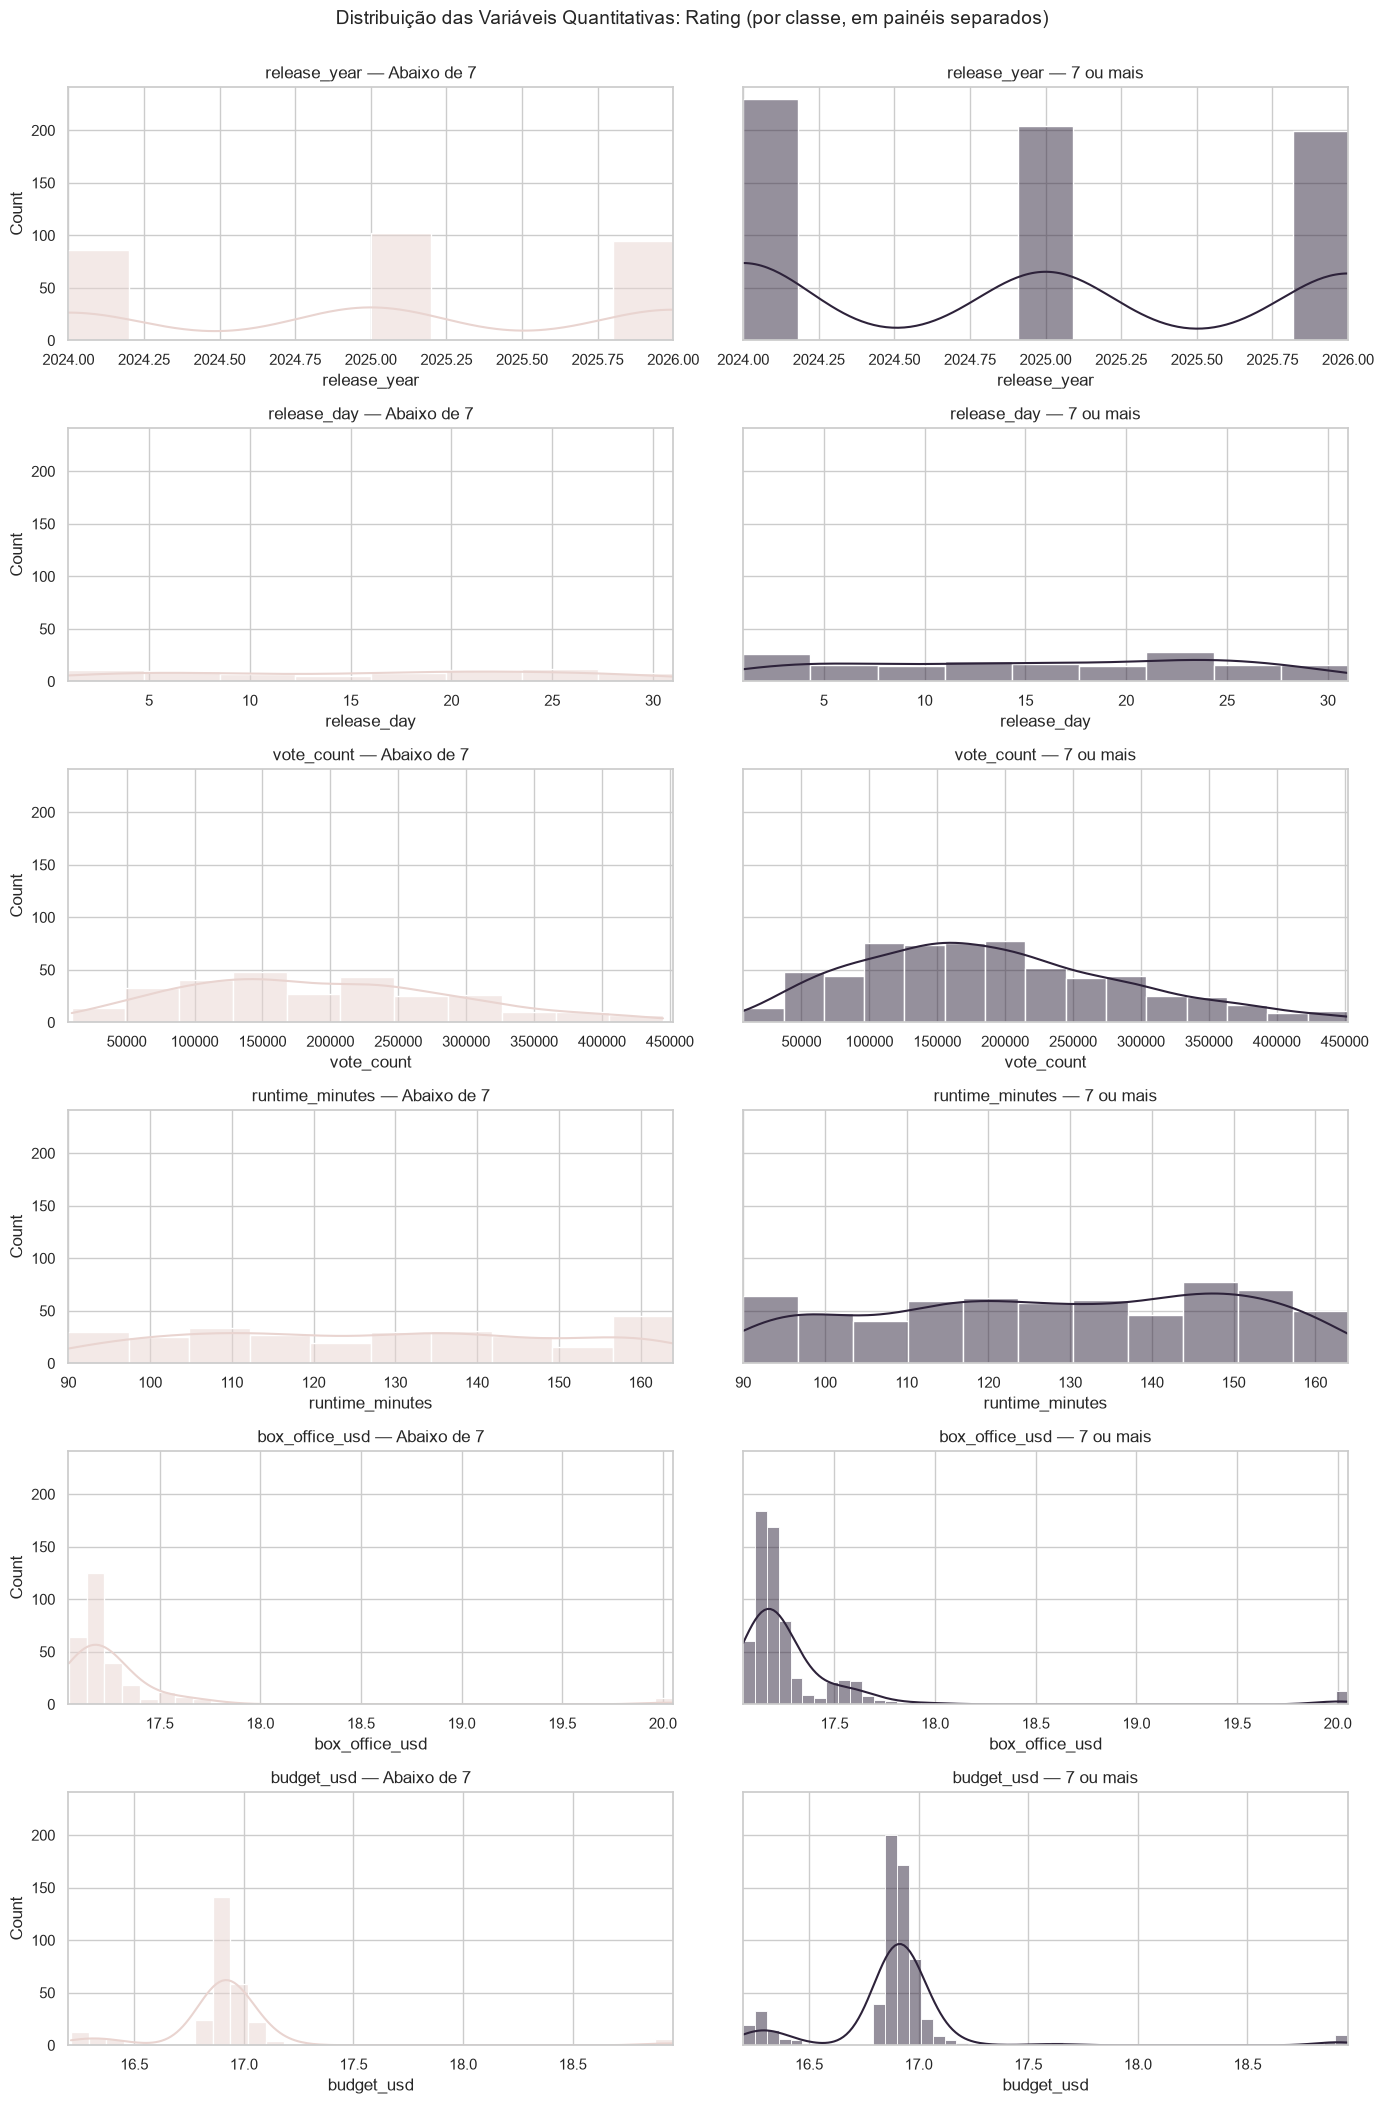

In [40]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(14, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Abaixo de 7", COR_CONTEXTO), ("7 ou mais", COR_DESTAQUE)]):
        subset = df[df["rating_out_of_10"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Rating (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Abaixo de 7" e "7 ou mais"?

release_year(ano de lançamento): a classe '7 ou mais' possui colunas mais altas do que a classe 'Abaixo de 7'

box_office_usd(bilheteria):  a classe '7 ou mais' possui picos mais altos do que a classe 'Abaixo de 7' e possui alguns pontos isolados próximos a 20.0

budget_usd(orçamento):a classe '7 ou mais' possui picos mais altos

#### Testes de Aderência

*Será se a contagem de votos(vote_count) segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `vote_count`.

Shapiro-Wilk — vote_count: estatística=0.9759, p-valor=3.575e-11
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


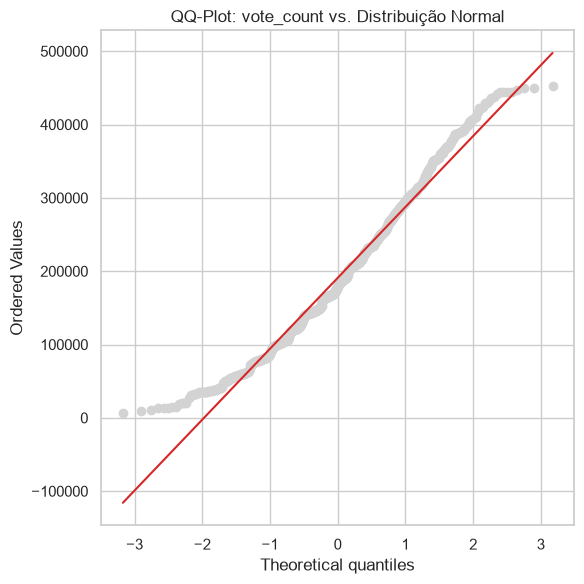

In [41]:
stat_sw, p_valor_sw = stats.shapiro(df["vote_count"].dropna())
print(f"Shapiro-Wilk — vote_count: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — vote_count"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["vote_count"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: vote_count vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [42]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
release_year,0.7932,0.0,True
release_day,0.9443,0.0,True
vote_count,0.9759,0.0,True
runtime_minutes,0.9550,0.0,True
box_office_usd,0.3835,0.0,True
budget_usd,0.5504,0.0,True


Como o teste rejeita H0, a afirmação estatística correta é que temos forte evidência estatística contra a normalidade de todas as variáveis do dataset. Por conta disso, para análises bivariadas futuras ou modelos preditivos, recomenda-se o uso de métodos não-paramétricos (como o teste de Mann-Whitney ou correlação de Spearman).

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`vote_count`, contagem de votos), só pra fixar como essa visualização se lê.

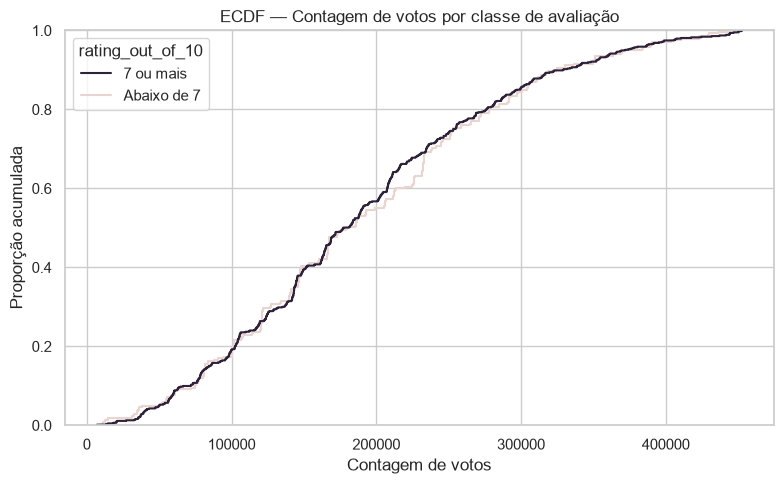

In [43]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="vote_count", hue="rating_out_of_10",
             palette={"Abaixo de 7": COR_CONTEXTO, "7 ou mais": COR_DESTAQUE})
plt.title("ECDF — Contagem de votos por classe de avaliação")
plt.xlabel("Contagem de votos")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem contagem de votos até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de contagem de votos onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

O comportamento acumulado do volume de votos é praticamente idêntico entre os filmes de nota alta e os de nota baixa. A probabilidade de um filme atingir uma determinada faixa de engajamento (votos) independe de sua classe de avaliação, confirmando que o volume de votantes não discrimina a nota da obra no catálogo.

### Métricas de Tendêncial Central

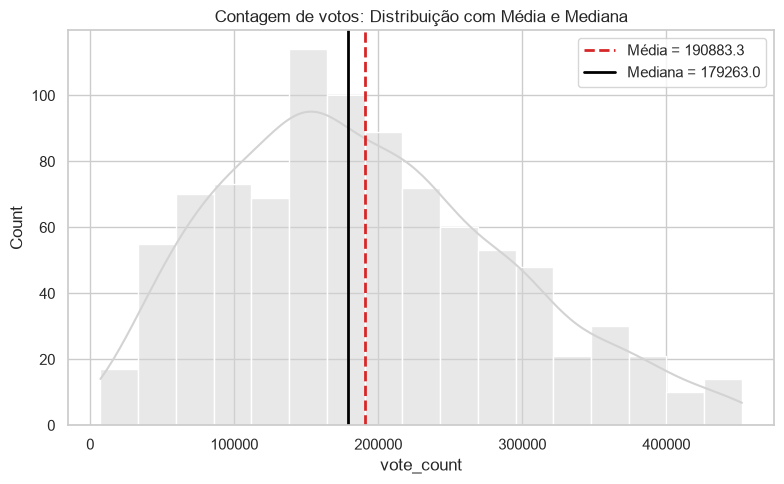

In [44]:
media_vote_count = df["vote_count"].mean()
mediana_vote_count = df["vote_count"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="vote_count", kde=True, color=COR_NEUTRA)
plt.axvline(media_vote_count, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_vote_count:.1f}")
plt.axvline(mediana_vote_count, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_vote_count:.1f}")
plt.title("Contagem de votos: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

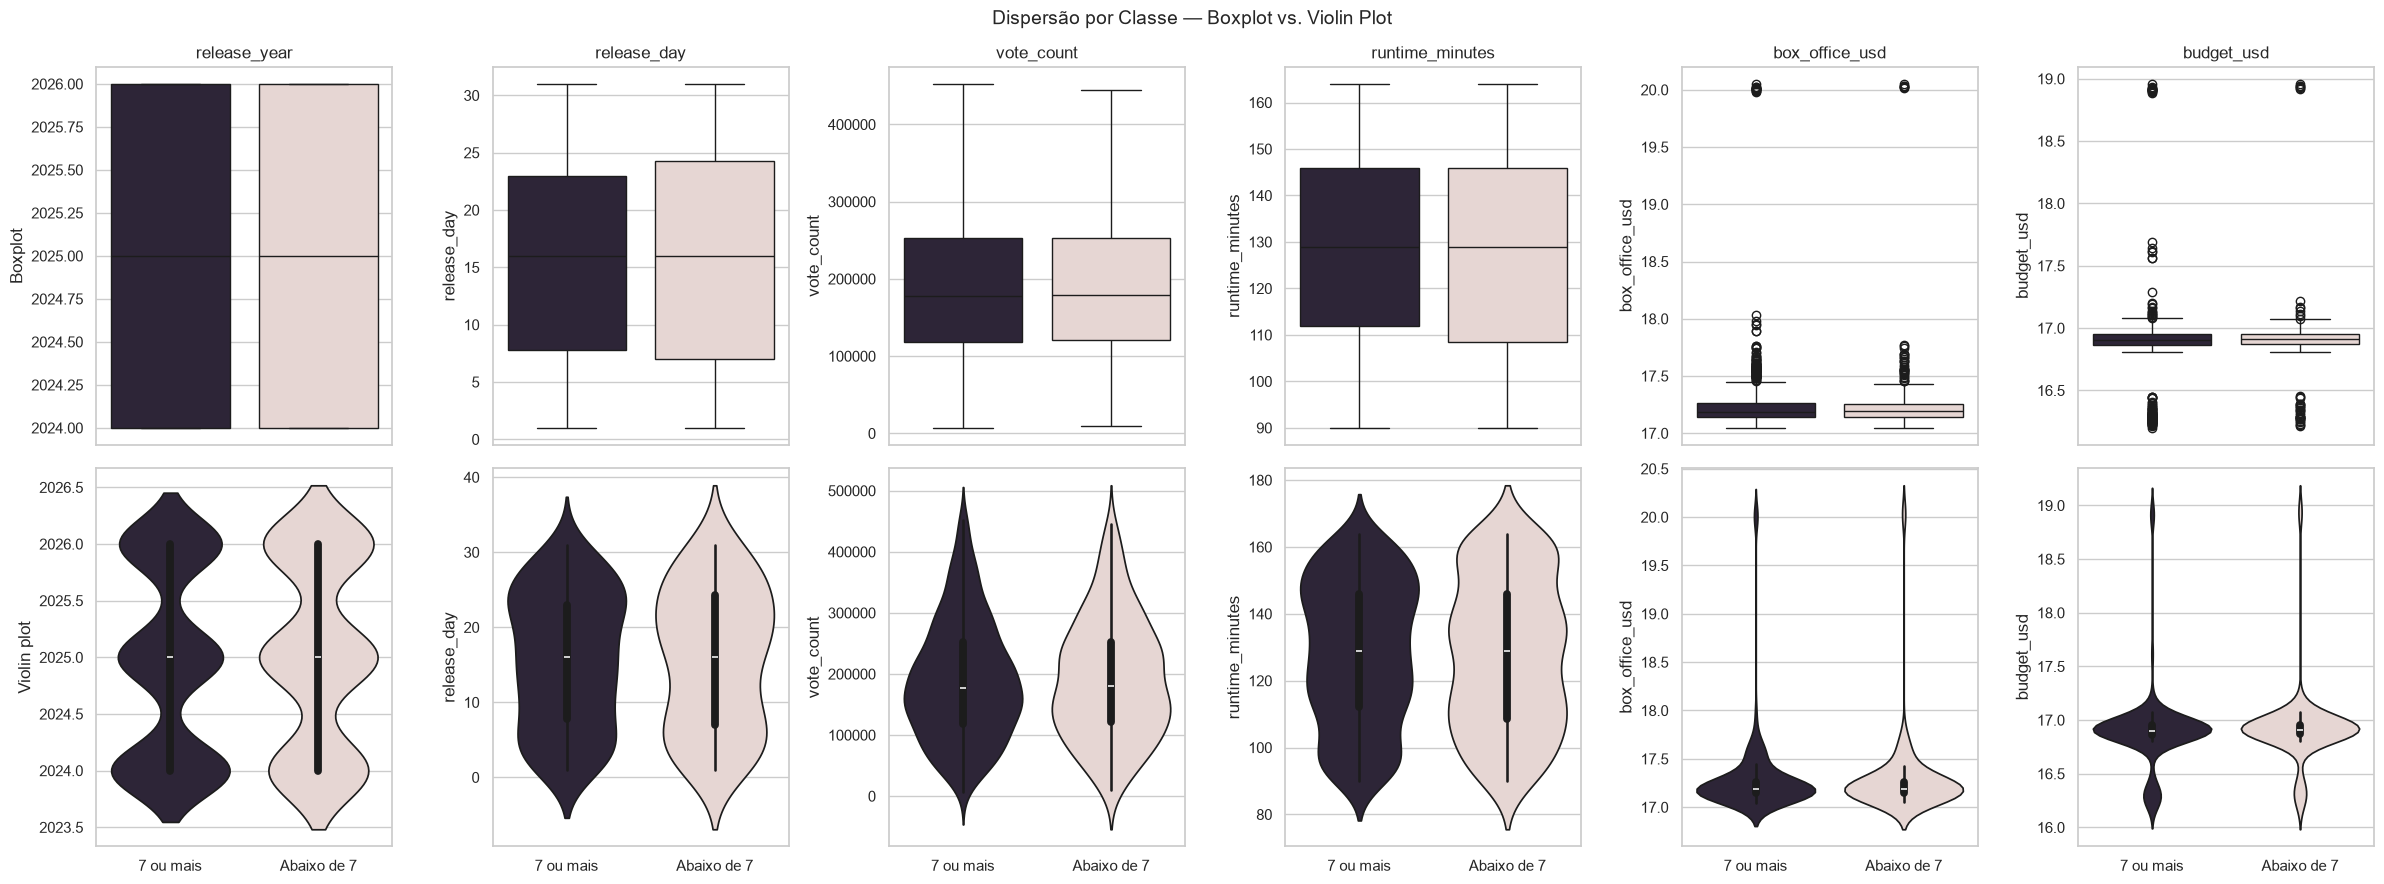

In [45]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Abaixo de 7": COR_CONTEXTO, "7 ou mais": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="rating_out_of_10", y=col, hue="rating_out_of_10",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="rating_out_of_10", y=col, hue="rating_out_of_10",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Abaixo de 7" e "7 ou mais"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Nenhuma variável isolada demonstra, por si só, um forte poder de separação direta entre os dois grupos apenas pelo IQR. Isso reforça a necessidade de avançar para a análise bivariada e testes de hipóteses não-paramétricos (como Mann-Whitney) para identificar diferenças estatísticas mais sutis

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`release_day`, `director`, `screenwriter`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [46]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 3 * iqr, q3 + 3 * iqr
    """Mudei para 3 porque tinha muito outlier"""

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
release_year,2018.00,2032.00,0.0
release_day,-44.00,75.00,0.0
vote_count,-283014.00,655171.50,0.0
runtime_minutes,5.00,251.75,0.0
box_office_usd,16.78,17.62,55.0
budget_usd,16.61,17.21,133.0


### Visualizando os Outliers

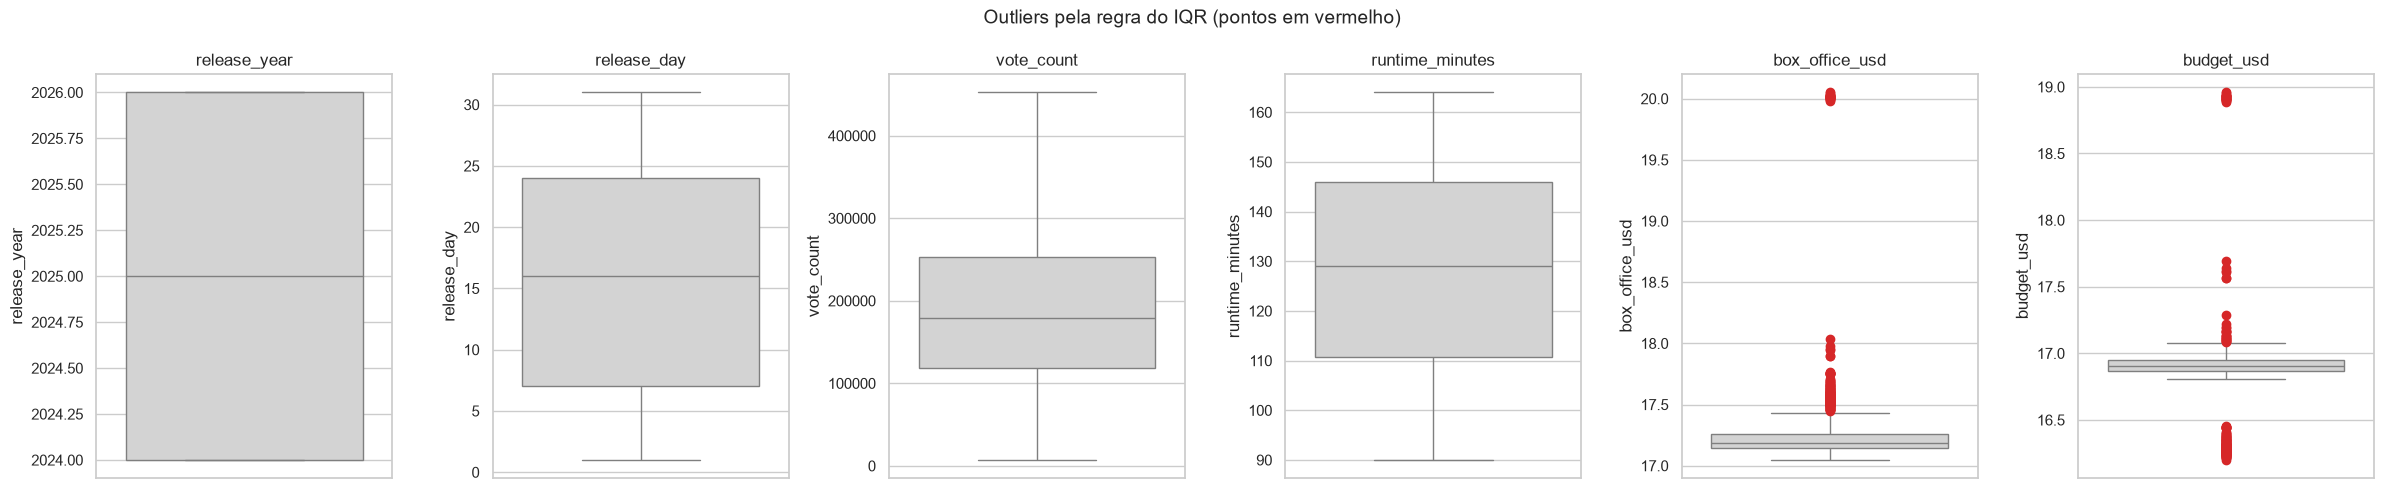

In [47]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `box_office_usd` e `budget_usd`): eles parecem fisiologicamente plausíveis , ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

Os outliers são plausíveis e se classificam como outliers estatísticos. Isso ocorre devido a grande variedade de orçamento e bilheteria que existe no entretenimento.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: Com a combinação de baixo volume de perdas e baixo risco de viés estatístico, a melhor conduta para o prosseguimento do projeto é realizar a remoção das linhas afetadas.

Manter o dataset limpo via exclusão dessas raras linhas é mais seguro e simples do que aplicar técnicas complexas de imputação, que poderiam introduzir ruídos indesejados em amostras pequenas sem trazer ganho significativo de poder estatístico.

In [48]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=VARS_QUANT + ["rating_out_of_10"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 916 | Linhas depois: 240 | Removidas: 676


### Decidindo o Tratamento dos Outliers

Diferente dos dados ausentes, aqui não vamos remover automaticamente. Pelos valores encontrados (dentro de faixas plenamente plausíveis para o mercado cinematográfico, ainda que raras, como os grandes blockbusters), a classificação mais provável é de Outliers Estatísticos — valores legítimos, e não erros de coleta ou digitação. Sendo assim, o tratamento recomendado nesse caso é manter (a informação é real e reflete a própria dinâmica da indústria do entretenimento, onde grandes produções naturalmente concentram orçamentos e bilheterias desproporcionais) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), transformar.

Foram mantidos os valores originais, eu apenas fiz uma transformação logarítmica em box_office_usd e budget_usd para facilitar minhas análises

In [49]:
df["box_office_usd"] = np.log(df["box_office_usd"])
df["budget_usd"] = np.log(df["budget_usd"])

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [50]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
release_year,2024.98,2025.00,0.82,2024.00,2026.00,0.05,-1.52
release_day,15.68,16.00,9.01,1.00,31.00,-0.08,-1.26
vote_count,203618.97,193162.50,104793.07,13496.00,452490.00,0.37,-0.54
runtime_minutes,127.49,130.00,22.27,90.00,164.00,-0.15,-1.23
box_office_usd,2.86,2.85,0.04,2.84,3.00,3.05,8.01
budget_usd,2.83,2.83,0.03,2.79,2.94,2.31,5.88


### Comparando "antes"x "depois""



In [51]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
release_year,0.044,0.047,-1.497,-1.522,0.002,-0.025
release_day,-0.080,-0.080,-1.261,-1.261,0.000,0.000
vote_count,0.457,0.369,-0.366,-0.535,-0.089,-0.170
runtime_minutes,-0.085,-0.145,-1.168,-1.227,-0.061,-0.059
box_office_usd,5.348,3.048,30.363,8.006,-2.300,-22.357
budget_usd,3.101,2.308,17.215,5.875,-0.793,-11.340


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Os valores estatísticos das variáveis apresentaram alterações insignificantes após a etapa de tratamento. Essa estabilidade era plenamente esperada, visto que a remoção afetou um volume extremamente reduzido da base e optou-se por preservar integralmente os outliers estatísticos de bilheteria e orçamento, aplicando apenas a transformação logarítmica.

**O box_office_usd ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [52]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["box_office_usd"].dropna())
print(f"Shapiro-Wilk (antes)  — box_office_usd: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — box_office_usd: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — box_office_usd: estatística=0.9759, p-valor=3.575e-11
Shapiro-Wilk (depois) — box_office_usd: estatística=0.4732, p-valor=4.145e-26


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`box_office_usd` e `budget_usd`), comparando a versão original (`df_antes`) com a tratada (`df`).

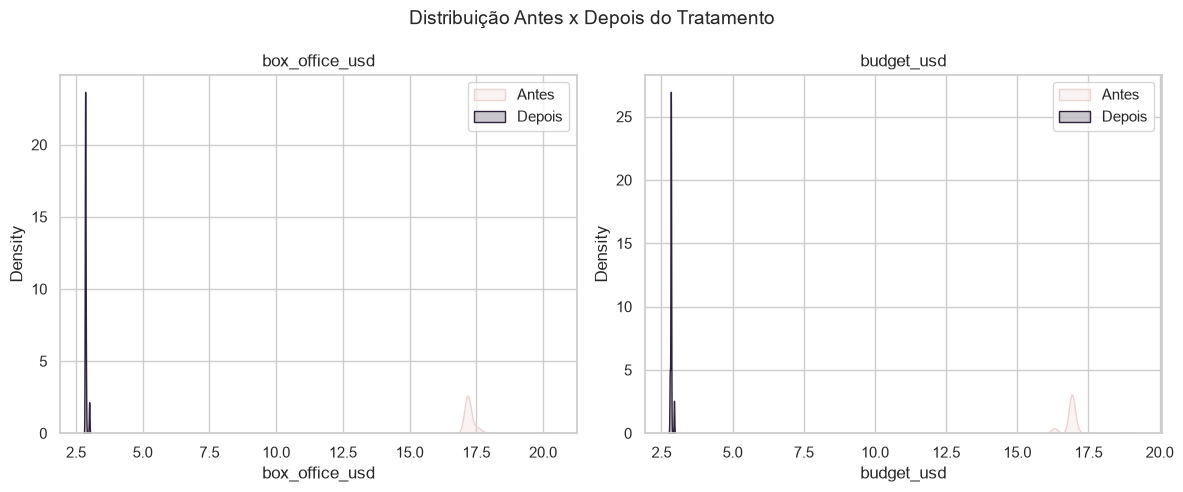

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["box_office_usd", "budget_usd"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Na análise do gráfico, nota-se o deslocamento do eixo X decorrente do reescalonamento logarítmico aplicado às variáveis box_office_usd e budget_usd.

Quando observamos o impacto isolado da limpeza de dados (remoção de ~2% de nulos), o comportamento e o formato da distribuição se preservam intactos. O fato de a estrutura da curva não sofrer deformações bruscas confirma que a estratégia foi conservadora: eliminou-se o ruído dos dados faltantes sem distorcer a realidade dos blockbusters nem introduzir viés na amostra.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [54]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- title ---
                         absoluta  relativa
title                                      
The Mummy Murders               1     0.004
DarkGame                        1     0.004
We Strangers                    1     0.004
The Beekeeper                   1     0.004
Wanted Man                      1     0.004
...                           ...       ...
Clarissa                        1     0.004
Avengers: Doomsday              1     0.004
The Angry Birds Movie 3         1     0.004
Jumanji: Open World             1     0.004
The Odyssey                     1     0.004

[240 rows x 2 columns]
\n--- release_month ---
               absoluta  relativa
release_month                    
March                27     0.112
July                 25     0.104
November             24     0.100
August               22     0.092
February             21     0.088
January              20     0.083
May                  20     0.083
October              19     0.079
April                18 

#### Visualizando as frequências

C:\Users\Aline M\AppData\Local\Temp\ipykernel_14200\353616649.py:10: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


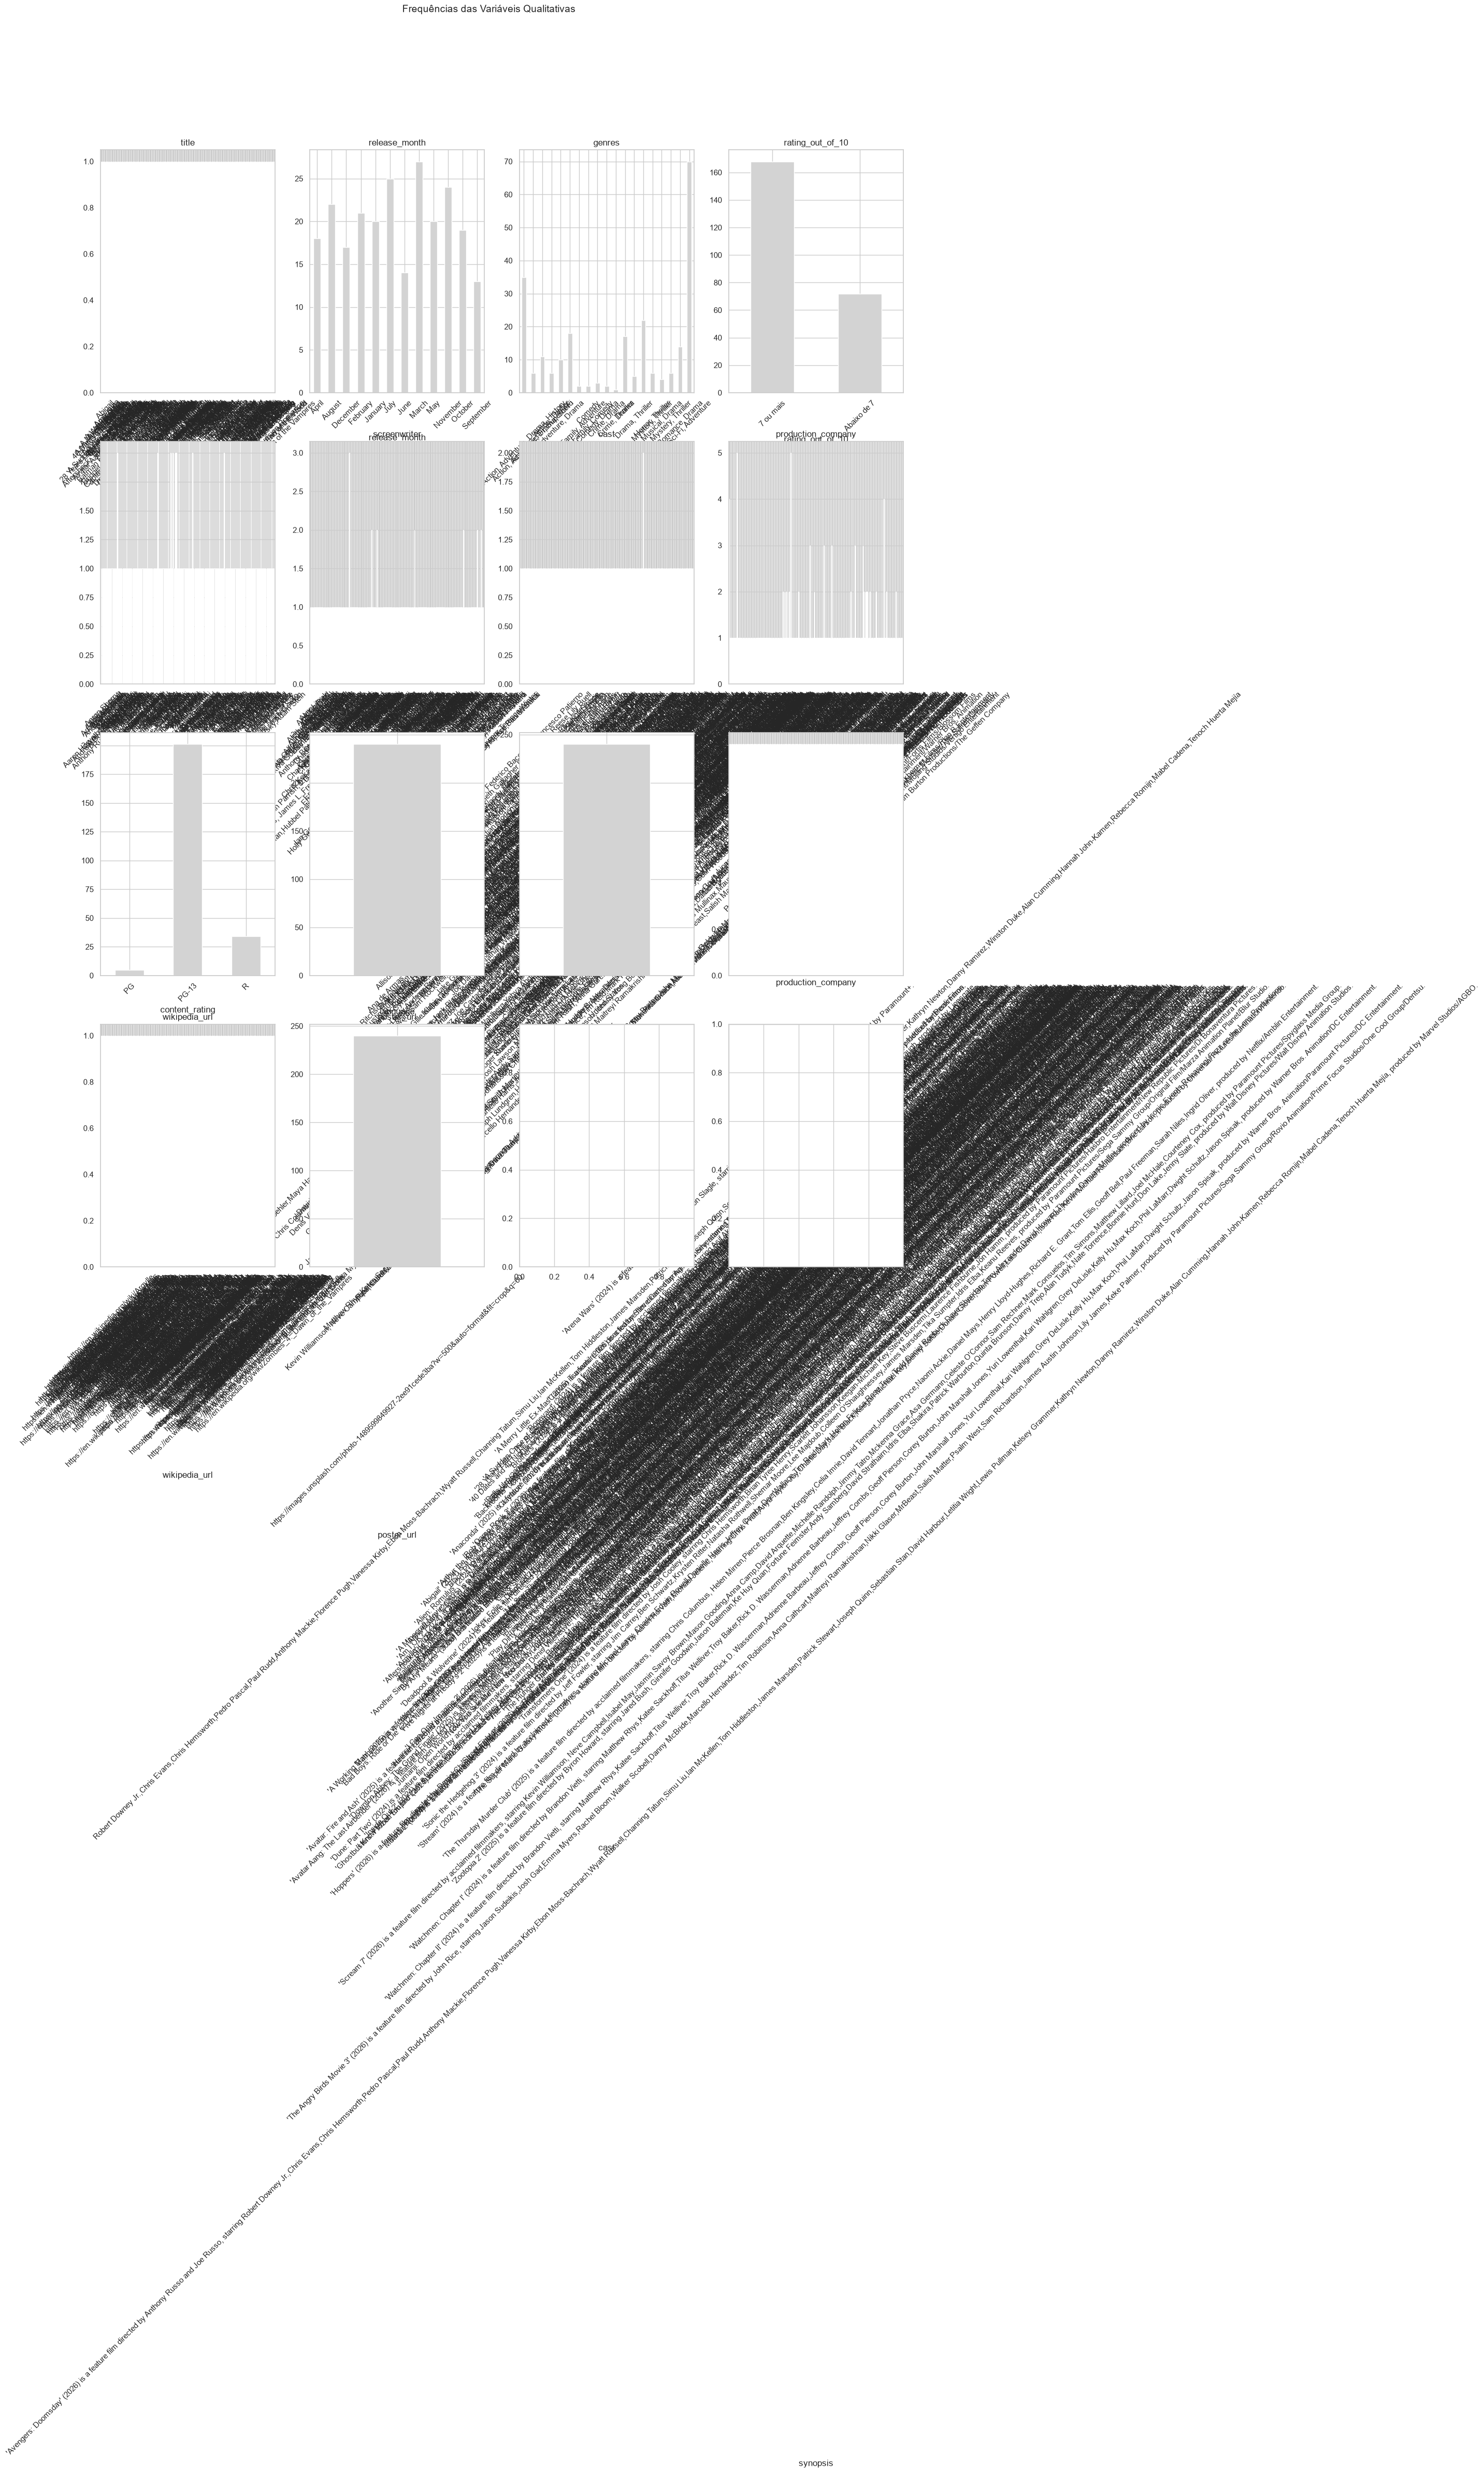

In [55]:
fig, axes = plt.subplots(4, 4, figsize=(20, 28), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Sim, identificou-se um forte desbalanceamento em variáveis como content_rating, language e country, nas quais uma única classe concentra quase a totalidade das observações do dataset


#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `rating_out_of_10`.

In [56]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["rating_out_of_10"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
title,240.0,1.00,1.000
release_month,12.0,2.08,0.992
genres,19.0,70.00,0.814
rating_out_of_10,2.0,2.33,0.881
director,160.0,2.00,0.997
screenwriter,228.0,3.00,0.997
cast,239.0,2.00,1.000
production_company,201.0,5.00,0.983
content_rating,3.0,40.20,0.461
language,1.0,1.00,NaN


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `rating_out_of_10` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Sim, a variável content_rating apresenta entropia bem próxima de 0 (0.461), além de language, country e poster_url que possuem entropia zerada/indefinida (NaN) por apresentarem apenas uma única classe (1.0). Isso confirma um desbalanceamento severo nestas variáveis categóricas.

Em relação ao alvo rating_out_of_10, ele está razoavelmente balanceado. Sua entropia de 0.881 (bastante próxima de 1.0) e a razão de desbalanceamento de apenas 2.33 indicam que a proporção entre suas duas classes é equilibrada o suficiente para não distorcer as análises bivariadas nem prejudicar o treinamento de modelos futuros.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'rating_out_of_10'.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos budget_usd x box_office_usd por um motivo de domínio, não só estatístico: existe uma relação comercial direta entre o orçamento investido na produção e a receita bruta obtida nas bilheterias, o que torna esse par um excelente candidato para visualizar uma tendência real de retorno financeiro.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

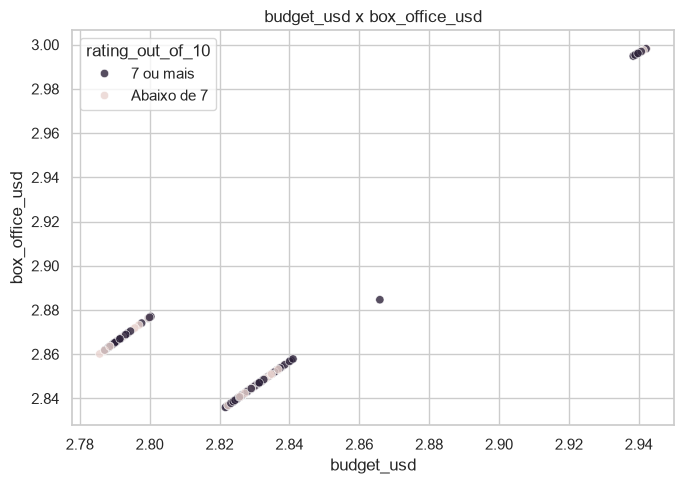

In [57]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="budget_usd", y="box_office_usd", hue="rating_out_of_10",
                palette={"Abaixo de 7": COR_CONTEXTO, "7 ou mais": COR_DESTAQUE}, alpha=0.8)
plt.title("budget_usd x box_office_usd")
plt.xlabel("budget_usd")
plt.ylabel("box_office_usd")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme o budget_usd aumenta, `box_office_usd` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

A tendência visual é de que conforme o budget_usd aumenta, a box_office_usd tende a subir (relação positiva), organizada em agrupamentos com inclinação ascendente.

Quanto às duas classes (7 ou mais e Abaixo de 7), elas estão completamente misturadas ao longo de todos os agrupamentos, sem ocupar regiões distintas do gráfico. Isso indica que a combinação isolada de orçamento e bilheteria não é suficiente para separar os filmes por nota.

#### Outliers bivariados

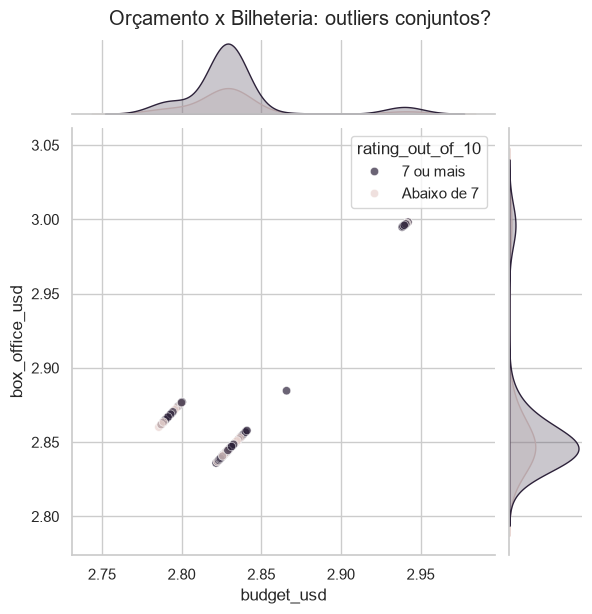

In [58]:
sns.jointplot(data=df, x="budget_usd", y="box_office_usd", hue="rating_out_of_10",
              palette={"Abaixo de 7": COR_CONTEXTO, "7 ou mais": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Orçamento x Bilheteria: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `budget_usd` e `box_office_usd`?

Sim, observam-se pontos isolados no gráfico. No canto superior direito, há filmes com orçamento e bilheteria desproporcionalmente mais altos do que o restante do grupo principal, revelando uma combinação extrema que passa despercebida nas análises univariadas isoladas.

#### Análise Multivariada

##### Matriz de Correlação

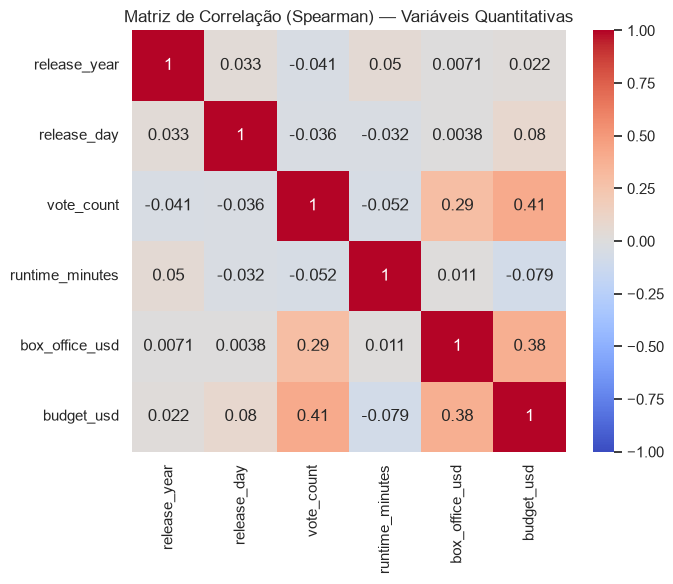

In [59]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Nesta matriz de Spearman, nenhuma correlação atinge o patamar de forte a ponto de sugerir redundância ou risco de multicolinearidade. O maior valor observado ocorre entre vote_count e budget_usd, seguido por box_office_usd e budget_usd, ambos classificados apenas como correlações moderadas. Portanto, todas as variáveis quantitativas trazem informações distintas e vale a pena mantê-las no dataset.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

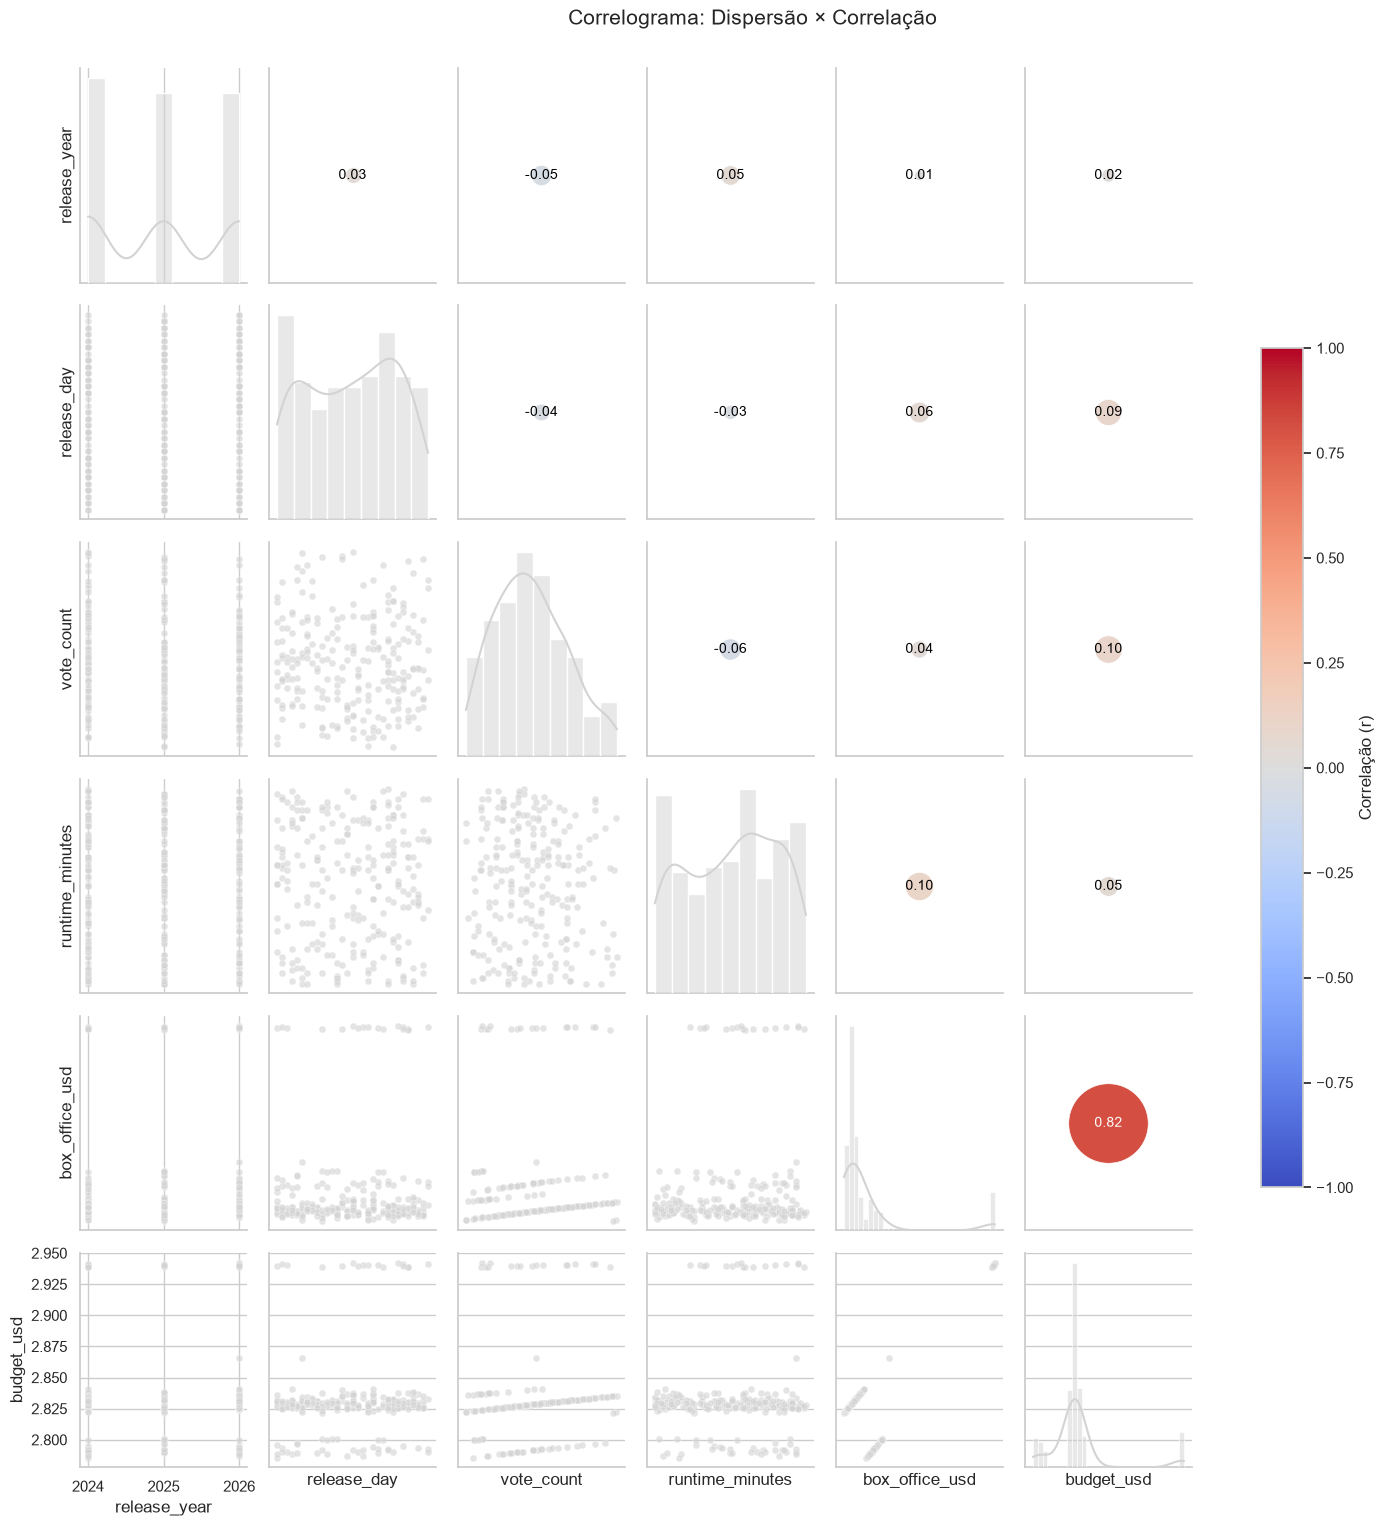

In [60]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos

2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Conclusões: Assimetria financeira acentuada: As variáveis de orçamento (budget_usd) e bilheteria (box_office_usd) apresentam uma forte distribuição assimétrica à direita, justificando a transformação logarítmica para estabilizar a variação nas análises estatísticas.

Segmentação por qualidade: A criação da variável categórica baseada nas avaliações (rating_out_of_10) divide de forma clara os títulos entre "Abaixo de 7" e "7 ou mais", permitindo comparar a performance comercial por faixas de aprovação do público.

Padrão coocorrente nas ausências: Os dados faltantes não são totalmente aleatórios; a matriz de contingência demonstra que campos como director e screenwriter costumam estar ocultos ou ausentes nos mesmos registros.

Declaração do uso de IA: use para me auxiliar nos textos e nos códigos para ficar mais coerente (gemini e chatgpt)

In [61]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [62]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
path = kagglehub.dataset_download(
    "rewantbhriguvanshi/recent-movies-and-entertainment-dataset-20242026"
)

# Carregar CSV
df_raw= pd.read_csv(
    os.path.join(path, "recent_movies_2024_2026.csv")
)

df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 916 linhas x 20 colunas


In [63]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 240 linhas x 20 colunas
Linhas removidas no tratamento: 676
